# EDA -> DSC PJATK Catalogue Quality Challenge

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
oof = pd.read_csv("../data/handoff/oof_tree_v2.csv")

In [61]:
train.shape, test.shape, oof.shape

((16000, 11), (10000, 10), (16000, 5))

In [62]:
train.head()

,id,seller_id,title,description,declared_category,brand,condition,price_pln,shipping_weight_kg,pack_size,target
0,OFR_191714271,SEL_7523257,recording mic support — pack of one — Mira A513,Pack of one main items. Microphone stand by Mi...,audio,Mira,used,70.43,5.233,1.0,1
1,OFR_517640949,SEL_2053194,in-ear cable headphones — quantity 2 — Noro E315,Included main items: 2. Wired earbuds by Noro....,computers,Noro,used,28.95,0.119,2.0,1
2,OFR_634805877,SEL_8620752,Tenso digital food balance / standard / quanti...,Included main items: 1. Kitchen scale by Tenso...,kitchen,Tenso,new,62.05,0.412,1.0,0
3,OFR_643990737,SEL_8396386,litter scoop — five main items — Velo ...,Cat tray cleaning shovel by Velto. Variant: st...,pets,Velto,used,102.26,0.499,5.0,0
4,OFR_260742748,SEL_5029882,LAPTOP SLEEVE — PACK OF FIVE — ASTER F219,Variant: standard. Also includes 3 pcs of free...,computers,Aster,used,144.84,0.856,5.0,0


In [63]:
train["target"].value_counts(normalize=True)

target
0    0.829937
1    0.170063
Name: proportion, dtype: float64

Tutaj mamy procent ile ofert ma błąd (83% poprawnych i 17% z błędem)

## Braki danych

In [64]:
train.isna().mean().sort_values(ascending=False)

shipping_weight_kg    0.060125
brand                 0.059187
description           0.042500
price_pln             0.038937
pack_size             0.030312
title                 0.029375
declared_category     0.023375
seller_id             0.000000
id                    0.000000
condition             0.000000
target                0.000000
dtype: float64

In [65]:
print(train.isna().groupby(train["target"]).mean().T.sort_values(1, ascending=False).round(3))

target                  0      1
shipping_weight_kg  0.060  0.062
brand               0.060  0.054
price_pln           0.038  0.043
description         0.044  0.037
pack_size           0.030  0.032
title               0.030  0.026
declared_category   0.023  0.025
seller_id           0.000  0.000
id                  0.000  0.000
condition           0.000  0.000
target              0.000  0.000


Braki występują w 2–6% wartości, najwięcej w wadze i marce. Odsetek braków jest prawie taki sam w ofertach poprawnych i błędnych, więc brak danych nie jest sygnałem błędu.

## Kategorie

In [66]:
train.groupby("declared_category", dropna=False)["target"].agg(["mean", "count"]).sort_values("mean", ascending=False)

,mean,count
declared_category,,
music,0.365986,735
garden,0.211119,1331
NaN,0.181818,374
kitchen,0.172659,2253
pets,0.172654,863
computers,0.159841,2759
beauty,0.159063,1622
audio,0.149901,2535
sport,0.139902,1837


In [67]:
train[(train["declared_category"] == "music") & (train["target"] == 1)][["title", "declared_category"]].head(10)

,title,declared_category
167,Mira C640: large tambourine (pack of three),music
241,Velto E280: standard multiport computer adapte...,music
493,EXTERNAL SSD — 1 UNITS — VELTO F364,music
501,ireless headphones — 1-pack — Noro D396,music
503,COMPUTER CALL HEADPHONES — ONE MAIN ITEM...,music
586,Tenso D359: standard external SSD (1 units),music
590,POETRY COLLECTION — PACK OF THREE — MIRA B672,music
606,Tenso mechanical keyboard / standard / pack of...,music
608,audio interface — pack of two — Mira E272,music
809,OVER-EAR BLUETOOTH HEDSET — QUANTITY 1 — NORO ...,music


Kategoria music ma 37% błędów (średnio 17%). Wśród błędnych ofert music większość tytułów to produkty z innych kategorii (SSD, słuchawki, książki), więc częstym błędem jest podmieniona kategoria. Tekst jest zaszumiony: literówki, twarde spacje, różne formaty liczby sztuk.

In [68]:
train[(train["declared_category"] == "music") & (train["target"] == 0)][["title", "declared_category"]].head(10)

,title,declared_category
80,Velto clip-on pitch meter / compact / three ma...,music
101,Velto D454: standard folding sheet holder (pac...,music
140,recording mic support — 1 units — Tenso C750,music
159,TENSO C438: LARGE FOLDING SHEET HOLDER (PACK O...,music
163,Mira USB microphone / standard / one main items,music
201,Aster wooden percussion beaters / large / one ...,music
259,USB MICROPHONE — PACK OF TWO — TENSO E622,music
296,Mira E477: standard printed piano score collec...,music
336,Tenso hand percussion frame / large / pack of one,music
361,VELTO A636: STANDARD CLIP-ON PITCH METER (QUAN...,music


Poprawne oferty music to faktycznie sprzęt muzyczny (mikrofony, nuty, perkusja), co potwierdza, że w błędnych ofertach kategoria została podmieniona.

## Ceny

In [69]:
train.groupby("target")["price_pln"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,12773.0,138.198523,182.783511,2.75,40.1600,77.250,162.1100,3049.33
1,2604.0,181.158157,316.288361,0.97,36.8925,79.805,192.2525,3464.27


Mediana cen jest podobna, ale ofert z błedem częsciej mają ceny skrajne, bardzo niskie albo bardzo wysokie. Błąd ceny to najpewniej jej mocne zawyżenie lub zaniżenie.

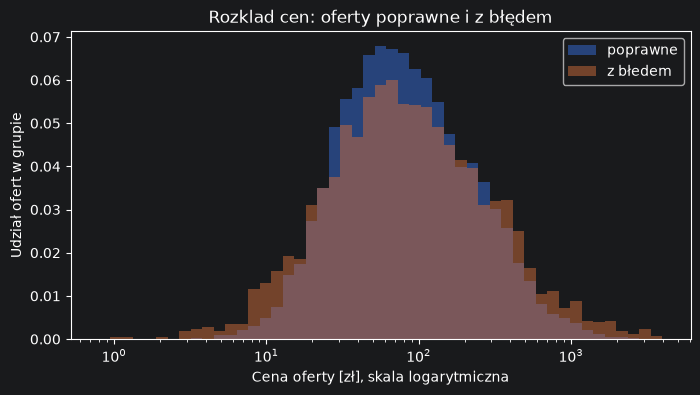

In [70]:
labels = {0: "poprawne", 1: "z błedem"}
bins = np.logspace(-0.1, 3.6, 50)


plt.figure(figsize=(8, 4))
for target_value in [0, 1]:
    prices = train.loc[train["target"] == target_value, "price_pln"].dropna()
    weights = np.ones(len(prices)) / len(prices)
    plt.hist(prices, bins=bins, weights=weights, alpha=0.5, label=labels[target_value])
    # Bez tego tanie oferty zbiłyby się w jeden słupek przy zerze, a drogie byłyby niewidoczne.

plt.xscale("log")
plt.xlabel("Cena oferty [zł], skala logarytmiczna")
plt.ylabel("Udział ofert w grupie")
plt.title("Rozklad cen: oferty poprawne i z błędem")
plt.legend()
plt.show()

Cena względem kategorii

In [71]:
category_median = train.groupby("declared_category")["price_pln"].transform("median")
train["price_vs_category"] = train["price_pln"] / category_median
train.groupby("target")["price_vs_category"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,12475.0,1.476920,1.633821,0.050802,0.558867,0.993358,1.777549,30.893711
1,2539.0,1.966086,3.236826,0.025300,0.498909,1.052933,2.176422,61.018955


ile ofert ma skrajną cene

In [72]:
extrema_price = (train["price_vs_category"] > 5) | (train["price_vs_category"] < 0.2)
extrema_price.groupby(train["target"]).mean()

target
0    0.056480
1    0.137817
Name: price_vs_category, dtype: float64

In [73]:
train["price_per_item"] = train["price_pln"] / train["pack_size"]
item_median = train.groupby("declared_category")["price_per_item"].transform("median")
train["item_price_vs_category"] = train["price_per_item"] / item_median
train.groupby("target")["item_price_vs_category"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,12098.0,1.311884,1.096558,0.066881,0.596971,1.011778,1.669668,16.351050
1,2455.0,1.647662,2.176322,0.028595,0.416111,0.909155,2.026432,30.936791


In [74]:
extrema_item = (train["item_price_vs_category"] > 5) | (train["item_price_vs_category"] < 0.2)
extrema_item.groupby(train["target"]).mean()

target
0    0.027788
1    0.138552
Name: item_price_vs_category, dtype: float64

Po przeliczeniu ceny na jedną sztukę skrajne ceny ma 2.8% poprawnych i 13.9% błędnych ofert (wcześniej 5.6% i 13.8%). Cena za sztukę daje o połowę mniej fałszywych alarmów, więc lepiej wskazuje błąd ceny niż cena całej paczki. W analizie pominięto oferty bez ceny, kategorii lub pack_size (ok. 1 450).

## Waga za sztukę względem kategorii